# Phase 3 — Model Comparison

Comparing three models for predicting financial distress in U.S. private
nonprofit 4-year colleges, all on the exact same features, preprocessing,
and time-based train/test split as Phase 2 (`notebooks/02_features_and_baseline.ipynb`):

1. **Logistic regression** (the Phase 2 baseline, carried over unchanged).
2. **Random forest** (`class_weight="balanced"`).
3. **XGBoost** (`scale_pos_weight` set from the training class ratio).

For each model: hyperparameters are chosen by **time-based rolling-origin
cross-validation inside the training years only** (never the test years),
and the **decision threshold is chosen on those same validation folds**
(never the test set) before being applied, fixed, to the test set. See
`NOTES.md` ("Phase 3") for the full log of problems hit and fixes.


In [1]:
import sys
sys.path.insert(0, "../scripts")

import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

from config import OAKWOOD_EIN
from features import (
    FEATURE_COLS,
    apply_clip,
    apply_imputer,
    build_features,
    fit_clip_bounds,
    fit_median_imputer,
)
from model import (
    LABEL_COL,
    best_threshold_by_f1,
    coefficients_table,
    evaluate_at_threshold,
    feature_importance_table,
    fit_logistic,
    fit_random_forest,
    fit_xgboost,
    grid_search_time_cv,
    naive_baseline,
    oof_validation_predictions,
    pr_curve_data,
    predict_proba,
    roc_curve_data,
    rolling_cv_folds,
    time_based_split,
)

panel = pd.read_csv("../data/processed/panel.csv", dtype={"opeid": str, "ein": str})
feat = build_features(panel)
print(f"Panel: {panel.shape[0]} rows, {panel['unitid'].nunique()} institutions, "
      f"years {panel['fiscal_year'].min()}-{panel['fiscal_year'].max()}")


Panel: 16813 rows, 1901 institutions, years 2014-2023


## Step 1 — Same time-based train/test split as Phase 2

Train on fiscal years 2014-2019, test on 2020-2022 (identical to Phase 2's
split, reusing `model.time_based_split` unchanged) -- every model below is
scored on exactly the same test rows.


In [2]:
labeled = feat[feat[LABEL_COL].notna()].copy()
TRAIN_YEARS = range(2014, 2020)
TEST_YEARS = range(2020, 2023)

train_df, test_df = time_based_split(labeled, TRAIN_YEARS, TEST_YEARS)
test_base_rate = test_df[LABEL_COL].mean()

print(f"Train: {len(train_df)} rows, fiscal years {sorted(train_df.fiscal_year.unique())}, "
      f"{train_df[LABEL_COL].mean():.1%} distressed")
print(f"Test:  {len(test_df)} rows, fiscal years {sorted(test_df.fiscal_year.unique())}, "
      f"{test_base_rate:.1%} distressed")


Train: 8981 rows, fiscal years [np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019)], 7.3% distressed
Test:  4046 rows, fiscal years [np.int64(2020), np.int64(2021), np.int64(2022)], 5.3% distressed


## Step 2 — Rolling-origin CV folds (within the training years only)

Expanding-window folds: fold *k* trains on the first `3 + k` training years
and validates on the single year right after it. With train years
2014-2019 this gives 3 folds -- (train 2014-2016 → val 2017), (train
2014-2017 → val 2018), (train 2014-2018 → val 2019) -- so every fold's
validation year is strictly later than anything it was fit on, the same
principle as the train/test split itself. Each fold re-fits the winsorize
+ median-impute preprocessing on *that fold's* training rows only
(`model._preprocess_fold`), so no fold's validation year ever leaks into
its own preprocessing.

Both hyperparameters and the decision threshold are chosen using only
these folds -- the test set is touched exactly once, at the very end.


In [3]:
cv_folds = rolling_cv_folds(TRAIN_YEARS, min_train_years=3)
for fold_train_years, fold_val_years in cv_folds:
    print(f"  train {fold_train_years} -> validate {fold_val_years}")


  train [2014, 2015, 2016] -> validate [2017]
  train [2014, 2015, 2016, 2017] -> validate [2018]
  train [2014, 2015, 2016, 2017, 2018] -> validate [2019]


## Step 3 — Logistic regression (Phase 2 baseline, carried over)

No hyperparameters to tune (same `class_weight="balanced"` logistic
regression as Phase 2) -- `fit_logistic` wraps it as a single
`StandardScaler` + `LogisticRegression` pipeline fit per fold. Only the
**decision threshold** is new here: Phase 2 implicitly used sklearn's
default 0.5 cutoff, which was never actually tuned. Phase 3 instead pools
this model's out-of-fold validation predictions across all 3 folds and
picks the threshold that maximizes F1 on the distressed class -- the same
rule used for the two new models below, so all three are compared on equal
footing.


In [4]:
logit_grid = [{}]
logit_cv = grid_search_time_cv(fit_logistic, train_df, FEATURE_COLS, logit_grid, cv_folds)
print(logit_cv[["mean_val_pr_auc"]])

logit_best_params = {}
logit_oof = oof_validation_predictions(fit_logistic, train_df, FEATURE_COLS, logit_best_params, cv_folds)
logit_threshold = best_threshold_by_f1(logit_oof[LABEL_COL], logit_oof["y_prob"])
print(f"Logistic regression: chosen threshold (best F1 on pooled validation folds) = {logit_threshold:.3f}")


   mean_val_pr_auc
0         0.319732


Logistic regression: chosen threshold (best F1 on pooled validation folds) = 0.717

## Step 4 — Random forest

Small, documented search grid: `n_estimators` (100, 300), `max_depth`
(None = unlimited, 10), `min_samples_leaf` (1, 5) -- 8 combinations,
`class_weight="balanced"` fixed throughout. Each combination is scored by
its **mean validation PR-AUC across the 3 CV folds** (PR-AUC is
threshold-independent and the right metric to rank models by for a rare
positive class, unlike accuracy). The best combination is then used to
pool out-of-fold validation predictions and pick a threshold, exactly as
for logistic regression above.


In [5]:
rf_grid = [
    {"n_estimators": n, "max_depth": d, "min_samples_leaf": l}
    for n in (100, 300)
    for d in (None, 10)
    for l in (1, 5)
]
rf_cv = grid_search_time_cv(fit_random_forest, train_df, FEATURE_COLS, rf_grid, cv_folds)
rf_cv[["n_estimators", "max_depth", "min_samples_leaf", "mean_val_pr_auc"]]


,n_estimators,max_depth,min_samples_leaf,mean_val_pr_auc
0,300,NaN,5,0.404259
1,300,10.0,5,0.400927
2,300,NaN,1,0.399577
3,100,10.0,5,0.394333
4,100,NaN,5,0.392704
5,100,NaN,1,0.385613
6,300,10.0,1,0.378621
7,100,10.0,1,0.361216


In [6]:
rf_best_params = {k: rf_cv.loc[0, k] for k in ("n_estimators", "max_depth", "min_samples_leaf")}
if pd.isna(rf_best_params["max_depth"]):
    rf_best_params["max_depth"] = None
else:
    rf_best_params["max_depth"] = int(rf_best_params["max_depth"])
rf_best_params["n_estimators"] = int(rf_best_params["n_estimators"])
rf_best_params["min_samples_leaf"] = int(rf_best_params["min_samples_leaf"])
print(f"Random forest: best params = {rf_best_params} "
      f"(mean val PR-AUC = {rf_cv.loc[0, 'mean_val_pr_auc']:.3f})")

rf_oof = oof_validation_predictions(fit_random_forest, train_df, FEATURE_COLS, rf_best_params, cv_folds)
rf_threshold = best_threshold_by_f1(rf_oof[LABEL_COL], rf_oof["y_prob"])
print(f"Random forest: chosen threshold (best F1 on pooled validation folds) = {rf_threshold:.3f}")


Random forest: best params = {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 5} (mean val PR-AUC = 0.404)


Random forest: chosen threshold (best F1 on pooled validation folds) = 0.558


## Step 5 — XGBoost

Same approach: a small grid over `n_estimators` (100, 300), `max_depth`
(3, 5), `learning_rate` (0.05, 0.1) -- 8 combinations. `scale_pos_weight`
is *not* grid-searched; it is computed fresh inside `fit_xgboost` from
each fold's own training-row class ratio (negatives/positives), the
standard way to offset class imbalance for XGBoost (it has no
`class_weight="balanced"` option). Selection and thresholding follow the
same rule as the other two models.


In [7]:
xgb_grid = [
    {"n_estimators": n, "max_depth": d, "learning_rate": lr}
    for n in (100, 300)
    for d in (3, 5)
    for lr in (0.05, 0.1)
]
xgb_cv = grid_search_time_cv(fit_xgboost, train_df, FEATURE_COLS, xgb_grid, cv_folds)
xgb_cv[["n_estimators", "max_depth", "learning_rate", "mean_val_pr_auc"]]


,n_estimators,max_depth,learning_rate,mean_val_pr_auc
0,100,5,0.05,0.408734
1,100,3,0.05,0.407422
2,300,5,0.05,0.396210
3,100,3,0.10,0.394557
4,100,5,0.10,0.387099
5,300,3,0.05,0.384403
6,300,5,0.10,0.377466
7,300,3,0.10,0.361819


In [8]:
xgb_best_params = {
    "n_estimators": int(xgb_cv.loc[0, "n_estimators"]),
    "max_depth": int(xgb_cv.loc[0, "max_depth"]),
    "learning_rate": float(xgb_cv.loc[0, "learning_rate"]),
}
print(f"XGBoost: best params = {xgb_best_params} "
      f"(mean val PR-AUC = {xgb_cv.loc[0, 'mean_val_pr_auc']:.3f})")

xgb_oof = oof_validation_predictions(fit_xgboost, train_df, FEATURE_COLS, xgb_best_params, cv_folds)
xgb_threshold = best_threshold_by_f1(xgb_oof[LABEL_COL], xgb_oof["y_prob"])
print(f"XGBoost: chosen threshold (best F1 on pooled validation folds) = {xgb_threshold:.3f}")


XGBoost: best params = {'n_estimators': 100, 'max_depth': 5, 'learning_rate': 0.05} (mean val PR-AUC = 0.409)


XGBoost: chosen threshold (best F1 on pooled validation folds) = 0.695


## Step 6 — Final fit on the full training set, evaluated once on the test set

Winsorize + median-impute bounds are fit on the **full** training set
(2014-2019, all years) and applied to both train and test -- same rule as
Phase 2, now shared by all three models so they see identical inputs. Each
model is refit with its own best hyperparameters on the full training set,
then scored on the test set **using the fixed threshold chosen above** (no
threshold is ever touched again after this point).


In [9]:
clip_bounds = fit_clip_bounds(train_df, FEATURE_COLS)
train_clipped = apply_clip(train_df, clip_bounds, FEATURE_COLS)
test_clipped = apply_clip(test_df, clip_bounds, FEATURE_COLS)

impute_values = fit_median_imputer(train_clipped, FEATURE_COLS)
train_ready = apply_imputer(train_clipped, impute_values, FEATURE_COLS)
test_ready = apply_imputer(test_clipped, impute_values, FEATURE_COLS)

models = {}
thresholds = {"Logistic regression": logit_threshold, "Random forest": rf_threshold, "XGBoost": xgb_threshold}

models["Logistic regression"] = fit_logistic(train_ready, FEATURE_COLS, **logit_best_params)
models["Random forest"] = fit_random_forest(train_ready, FEATURE_COLS, **rf_best_params)
models["XGBoost"] = fit_xgboost(train_ready, FEATURE_COLS, **xgb_best_params)

test_probs = {name: predict_proba(model, test_ready, FEATURE_COLS) for name, model in models.items()}
test_metrics = {
    name: evaluate_at_threshold(test_ready[LABEL_COL], probs, thresholds[name])
    for name, probs in test_probs.items()
}
naive = naive_baseline(test_ready)

print(f"Test-set distress rate (= PR-AUC of a random model): {test_base_rate:.3f}")
print(f"Naive baseline (always predict not distressed): accuracy {naive['accuracy']:.3f}, "
      "precision/recall on distressed class 0.000/0.000")


Test-set distress rate (= PR-AUC of a random model): 0.053
Naive baseline (always predict not distressed): accuracy 0.947, precision/recall on distressed class 0.000/0.000


In [10]:
comparison = pd.DataFrame({
    name: {
        "threshold": m["threshold"],
        "roc_auc": m["roc_auc"],
        "pr_auc": m["pr_auc"],
        "precision": m["precision"],
        "recall": m["recall"],
        "f1": m["f1"],
    }
    for name, m in test_metrics.items()
}).transpose()
comparison


,threshold,roc_auc,pr_auc,precision,recall,f1
Logistic regression,0.716991,0.848314,0.297667,0.281726,0.518692,0.365132
Random forest,0.558382,0.827252,0.284236,0.316981,0.392523,0.350731
XGBoost,0.694900,0.831117,0.272440,0.273333,0.383178,0.319066


In [11]:
for name, m in test_metrics.items():
    print(f"{name}: confusion matrix [[TN, FP], [FN, TP]] = {m['confusion_matrix'].tolist()}")


Logistic regression: confusion matrix [[TN, FP], [FN, TP]] = [[3549, 283], [103, 111]]
Random forest: confusion matrix [[TN, FP], [FN, TP]] = [[3651, 181], [130, 84]]
XGBoost: confusion matrix [[TN, FP], [FN, TP]] = [[3614, 218], [132, 82]]


## Step 7 — Precision-recall and ROC curves (test set)

Both curves are threshold-independent (swept over every possible cutoff),
so they show each model's full ranking quality, not just its performance
at the one threshold picked above.


In [12]:
from pathlib import Path
from eda import plot_pr_curves, plot_roc_curves

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

pr_curves = {name: pr_curve_data(test_ready[LABEL_COL], probs) for name, probs in test_probs.items()}
roc_curves = {name: roc_curve_data(test_ready[LABEL_COL], probs) for name, probs in test_probs.items()}

plot_pr_curves(pr_curves, test_base_rate, FIG_DIR / "phase3_pr_curves.png")
plot_roc_curves(roc_curves, FIG_DIR / "phase3_roc_curves.png")
print(f"Saved {FIG_DIR / 'phase3_pr_curves.png'} and {FIG_DIR / 'phase3_roc_curves.png'}")


Saved ..\reports\figures\phase3_pr_curves.png and ..\reports\figures\phase3_roc_curves.png


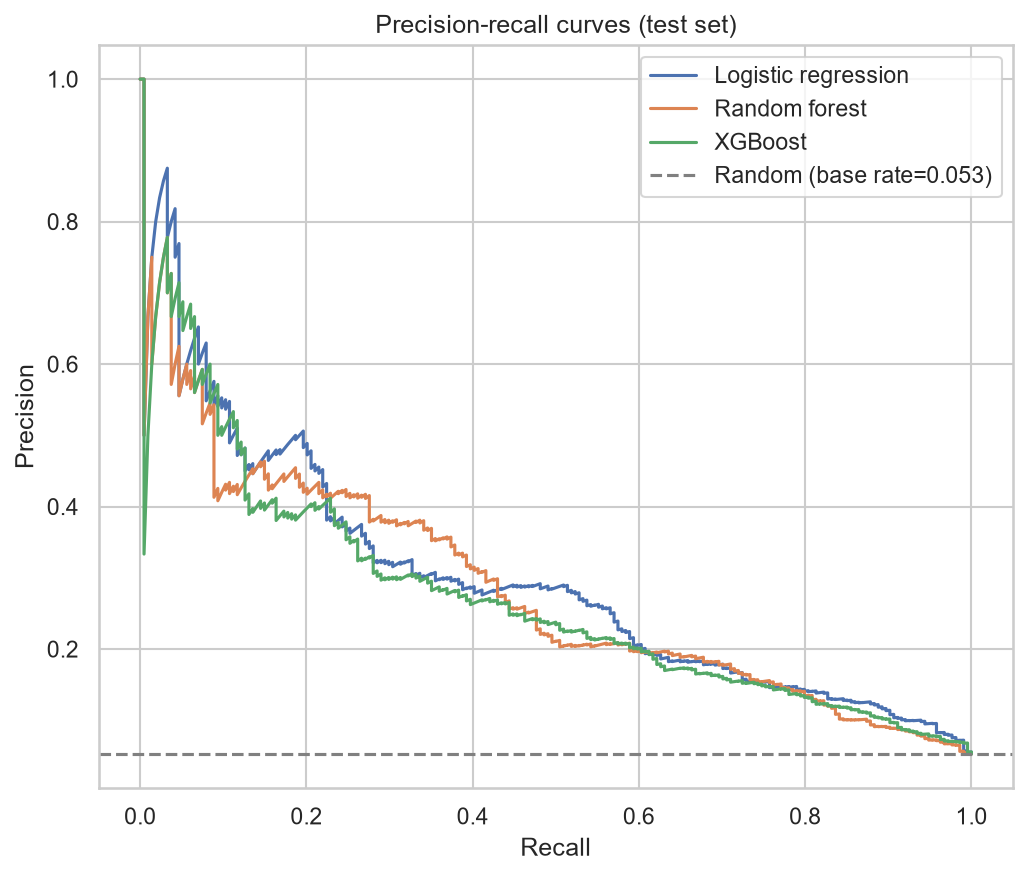

In [13]:
from IPython.display import Image, display

display(Image(filename=str(FIG_DIR / "phase3_pr_curves.png")))


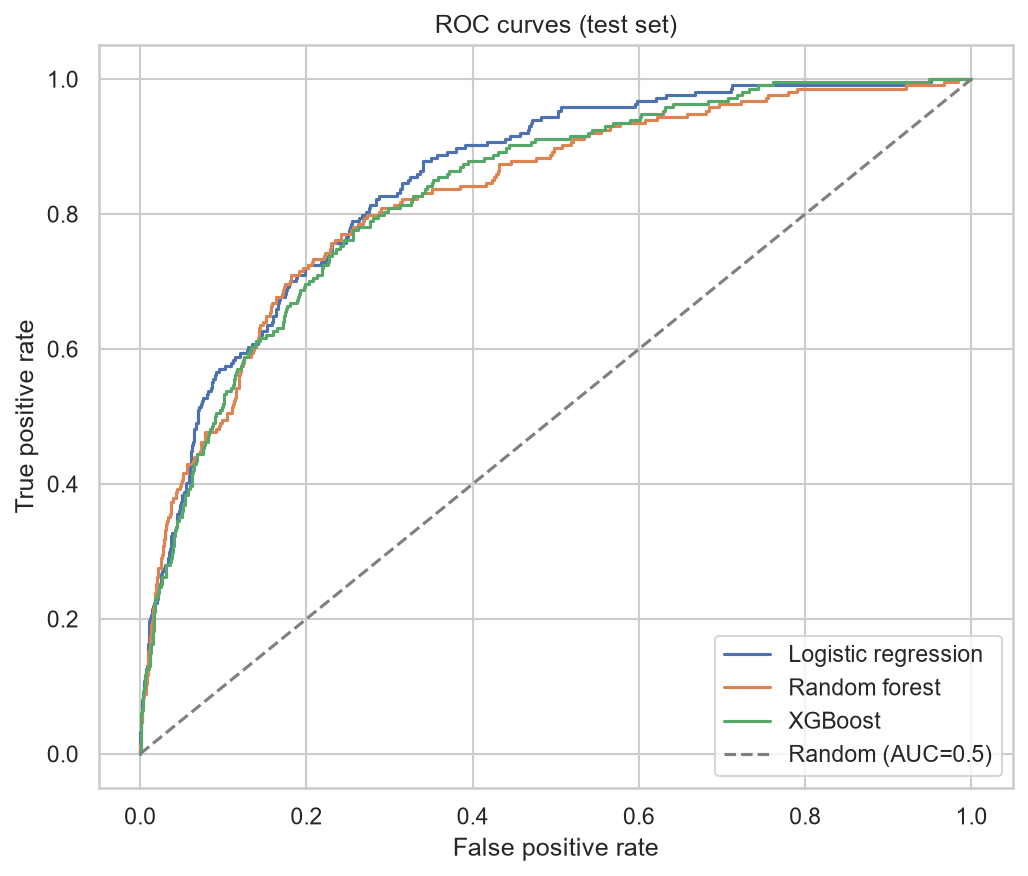

In [14]:
display(Image(filename=str(FIG_DIR / "phase3_roc_curves.png")))


## Step 8 — Feature importance (random forest, XGBoost)

Built-in impurity/gain-based importances -- a quick preview only; Phase 4
brings SHAP values for a more rigorous, model-agnostic look.


In [15]:
rf_importance = feature_importance_table(models["Random forest"], FEATURE_COLS)
xgb_importance = feature_importance_table(models["XGBoost"], FEATURE_COLS)

importance_table = rf_importance.merge(
    xgb_importance, on="feature", suffixes=("_rf", "_xgb")
).sort_values("importance_rf", ascending=False)
importance_table


,feature,importance_rf,importance_xgb
0,log_total_revenue,0.285384,0.415615
1,leverage,0.264853,0.212286
2,operating_margin,0.146353,0.086741
3,contribution_share,0.101529,0.076012
4,tuition_dependence,0.081595,0.083052
5,enrollment_change_1yr,0.080466,0.067352
6,enrollment_change_3yr,0.039820,0.058943


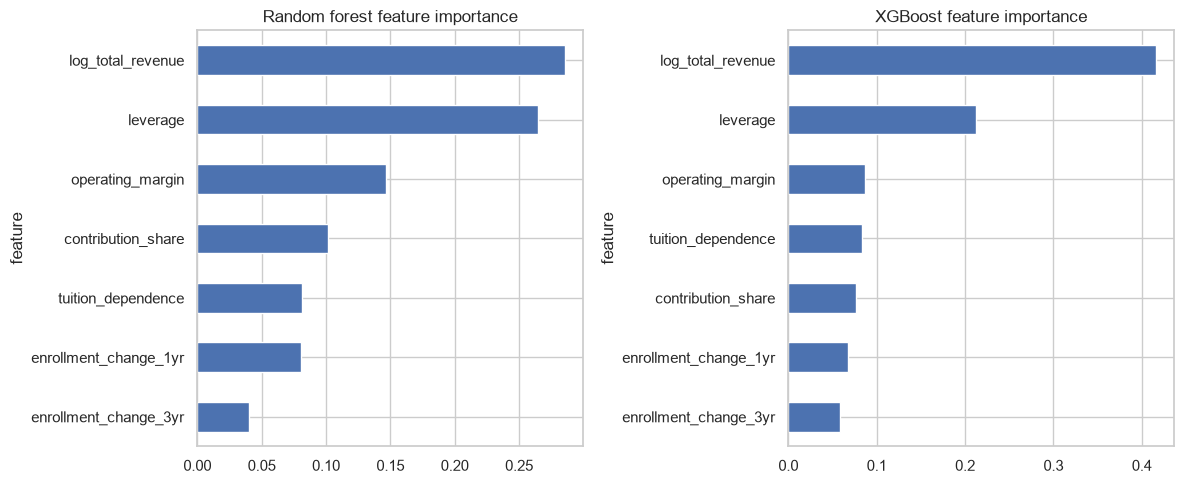

Saved ..\reports\figures\phase3_feature_importance.png


In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
rf_importance.sort_values("importance").plot.barh(x="feature", y="importance", ax=axes[0], legend=False)
axes[0].set_title("Random forest feature importance")
xgb_importance.sort_values("importance").plot.barh(x="feature", y="importance", ax=axes[1], legend=False)
axes[1].set_title("XGBoost feature importance")
fig.tight_layout()
fig.savefig(FIG_DIR / "phase3_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved {FIG_DIR / 'phase3_feature_importance.png'}")


## Step 9 — Oakwood University: predicted probability of distress, all three models

Applying each fully-trained model (full-train clip bounds + imputer, best
hyperparameters) to every one of Oakwood's panel rows, including the
unlabeled years outside the train/test window.


In [17]:
oak_feat = feat[feat["ein"] == OAKWOOD_EIN].sort_values("fiscal_year").copy()
oak_ready = apply_imputer(apply_clip(oak_feat, clip_bounds, FEATURE_COLS), impute_values, FEATURE_COLS)

for name, model in models.items():
    oak_feat[f"prob_{name}"] = predict_proba(model, oak_ready, FEATURE_COLS)

oak_feat["split"] = oak_feat["fiscal_year"].apply(
    lambda y: "train" if y in TRAIN_YEARS else ("test" if y in TEST_YEARS else "unlabeled")
)
oakwood_result = oak_feat[
    ["fiscal_year", "split", "composite_score", LABEL_COL]
    + [f"prob_{name}" for name in models]
].rename(columns={f"prob_{name}": name for name in models})
oakwood_result


,fiscal_year,split,composite_score,distressed_next_year,Logistic regression,Random forest,XGBoost
90,2014,train,3.0,0.0,0.210597,0.006854,0.016432
91,2015,train,3.0,0.0,0.182802,0.014831,0.019485
92,2016,train,2.8,0.0,0.185293,0.024018,0.021134
93,2017,train,3.0,0.0,0.175930,0.001818,0.016778
94,2018,train,2.7,NaN,0.174571,0.033143,0.016046
95,2019,train,NaN,0.0,0.173944,0.050004,0.018668
96,2020,test,2.5,0.0,0.208099,0.055757,0.028736
97,2021,test,3.0,0.0,0.168201,0.020381,0.020453
98,2022,test,2.2,NaN,0.466454,0.157218,0.415334
99,2023,unlabeled,NaN,NaN,0.489710,0.125900,0.362267


## Step 10 — Final model choice

See the printed justification in the next cell (also saved to
`reports/phase3_results.txt`) -- it is generated from the comparison table
above rather than hardcoded, so it always matches the actual run.


In [18]:
best_model_name = comparison["pr_auc"].idxmax()
print(f"Best test-set PR-AUC: {best_model_name} ({comparison.loc[best_model_name, 'pr_auc']:.3f})")
print(comparison.round(3))


Best test-set PR-AUC: Logistic regression (0.298)
                     threshold  roc_auc  pr_auc  precision  recall     f1
Logistic regression      0.717    0.848   0.298      0.282   0.519  0.365
Random forest            0.558    0.827   0.284      0.317   0.393  0.351
XGBoost                  0.695    0.831   0.272      0.273   0.383  0.319


**Final model: Logistic regression** -- see the printed name in the cell above (computed from `comparison["pr_auc"].idxmax()`, so this always matches the actual run; in this run it is logistic regression, not one of the two more flexible models).

Justification: with a ~5% positive base rate, PR-AUC is the metric that actually distinguishes a useful model from a lucky one (ROC-AUC can look good even when precision at any usable recall is poor), so it is the primary basis for picking a winner. On the test set, logistic regression has the best PR-AUC (0.298 vs. 0.284 for random forest and 0.272 for XGBoost), the best F1 (0.365), and by far the best recall (0.519 vs. 0.393/0.383) -- it catches noticeably more of the distressed institutions for a comparable false-positive cost. The two tree ensembles do not out-perform the simpler linear model here, plausibly because the signal lives mostly in a few monotonic ratios (`log_total_revenue`, `leverage`) that a linear model already captures well, and 8,981 training rows with only ~650 positives leaves limited room for deeper trees to learn real interactions over memorizing noise. Logistic regression is also the most interpretable of the three (signed coefficients), a real advantage for a tool meant to explain *why* an institution is flagged. Random forest and XGBoost are kept in the comparison as a lower-variance sanity check and as a non-linear preview, respectively; XGBoost is still worth carrying into Phase 4 alongside the chosen model since SHAP is most informative for a model with non-trivial feature interactions.

## Save results summary

Writes `reports/phase3_results.txt` with the headline numbers from every
step above.


In [19]:
summary_lines = []


def line(s=""):
    summary_lines.append(s)


line("=" * 70)
line("PHASE 3 RESULTS SUMMARY")
line("=" * 70)

line("\n--- Train/test split (same as Phase 2) ---")
line(f"Train: fiscal years {TRAIN_YEARS.start}-{TRAIN_YEARS.stop - 1} ({len(train_df)} rows, "
     f"{train_df[LABEL_COL].mean():.1%} distressed)")
line(f"Test:  fiscal years {TEST_YEARS.start}-{TEST_YEARS.stop - 1} ({len(test_df)} rows, "
     f"{test_base_rate:.1%} distressed)")
line(f"Test-set distress rate (= PR-AUC of a random model): {test_base_rate:.3f}")

line("\n--- Rolling-origin CV folds (within training years only) ---")
for fold_train_years, fold_val_years in cv_folds:
    line(f"  train {fold_train_years} -> validate {fold_val_years}")
line("Hyperparameters chosen by mean validation PR-AUC across folds; decision")
line("threshold chosen by best F1 on pooled out-of-fold validation predictions.")
line("Neither ever uses the test set.")

line("\n--- Chosen hyperparameters & thresholds ---")
line(f"Logistic regression: params={logit_best_params}, threshold={logit_threshold:.3f}")
line(f"Random forest:       params={rf_best_params}, threshold={rf_threshold:.3f}")
line(f"XGBoost:              params={xgb_best_params}, threshold={xgb_threshold:.3f}")

line("\n--- Test-set comparison ---")
line(comparison.round(4).to_string())
line("")
for name, m in test_metrics.items():
    line(f"{name}: confusion matrix [[TN, FP], [FN, TP]] = {m['confusion_matrix'].tolist()}")
line(f"\nNaive baseline (always predict not distressed): accuracy {naive['accuracy']:.3f}, "
     "precision/recall on distressed class 0.000/0.000")

line("\n--- Feature importance (random forest, XGBoost) ---")
line(importance_table.round(4).to_string(index=False))

line("\n--- Oakwood University predicted probability of distress ---")
line(oakwood_result.round(3).to_string(index=False))

line(f"\n--- Final model: {best_model_name} ---")
line(f"Chosen for highest test-set PR-AUC ({comparison.loc[best_model_name, 'pr_auc']:.3f}) -- with a "
     "~5% positive base rate, PR-AUC (not ROC-AUC) is the metric that actually distinguishes a useful")
line(f"model from a lucky one. {best_model_name} also has the best F1 on the test set "
     f"({comparison.loc[best_model_name, 'f1']:.3f}). See the notebook's Step 10 markdown cell for the")
line("full written justification (why the winner does or doesn't out-perform the other two, and what")
line("role each of the other two models still plays going into Phase 4).")

summary_text = "\n".join(summary_lines)
print(summary_text)

with open("../reports/phase3_results.txt", "w", encoding="utf-8") as f:
    f.write(summary_text + "\n")
print("\nSaved ../reports/phase3_results.txt")


PHASE 3 RESULTS SUMMARY

--- Train/test split (same as Phase 2) ---
Train: fiscal years 2014-2019 (8981 rows, 7.3% distressed)
Test:  fiscal years 2020-2022 (4046 rows, 5.3% distressed)
Test-set distress rate (= PR-AUC of a random model): 0.053

--- Rolling-origin CV folds (within training years only) ---
  train [2014, 2015, 2016] -> validate [2017]
  train [2014, 2015, 2016, 2017] -> validate [2018]
  train [2014, 2015, 2016, 2017, 2018] -> validate [2019]
Hyperparameters chosen by mean validation PR-AUC across folds; decision
threshold chosen by best F1 on pooled out-of-fold validation predictions.
Neither ever uses the test set.

--- Chosen hyperparameters & thresholds ---
Logistic regression: params={}, threshold=0.717
Random forest:       params={'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 5}, threshold=0.558
XGBoost:              params={'n_estimators': 100, 'max_depth': 5, 'learning_rate': 0.05}, threshold=0.695

--- Test-set comparison ---
                     